<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_12SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [ ]:
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False

# монтируем Google Drive и определяем ARTIFACTS / DATA_ROO
IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/cv_lab12")
except Exception:
    # локальный запуск вне Colab (или Drive недоступен)
    DRIVE_ROOT = Path(os.getenv("CV_LAB12_ROOT", "cv_lab12"))

# артефакты (манифесты, features, метрики, bonus.md)
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", DRIVE_ROOT / "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# данные (реальные фото PixMo-Count, синтетические PNG, манифесты)
DATA = Path(os.getenv("CV_DATA", DRIVE_ROOT / "data" / "lab12"))
DATA.mkdir(parents=True, exist_ok=True)
IMG_DIR = DATA / "synth_images"; IMG_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED)

def save_json(name, data):
    (ARTIFACTS / name).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, default=str))

def save_jsonl(name, rows):
    (ARTIFACTS / name).write_text(
        ''.join(json.dumps(r, ensure_ascii=False, default=str) + '\n' for r in rows))

print(f"IN_COLAB={IN_COLAB}")
print(f"DRIVE_ROOT={DRIVE_ROOT}")
print(f"ARTIFACTS={ARTIFACTS}")
print(f"DATA={DATA}")

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

Mounted at /content/drive
IN_COLAB=True
DRIVE_ROOT=/content/drive/MyDrive/cv_lab12
ARTIFACTS=/content/drive/MyDrive/cv_lab12/artifacts
DATA=/content/drive/MyDrive/cv_lab12/data/lab12


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
%pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets \ torch torchvision scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


PALETTE: {'red': (220, 40, 40), 'green': (40, 180, 70), 'blue': (40, 90, 220), 'yellow': (240, 210, 40), 'purple': (150, 60, 200), 'orange': (240, 140, 30)}
render signature: Рендерит список {shape,color,radius,cx,cy} без перекрытий.
demo: no overlap -> True
demo image size: (256, 256) RGB


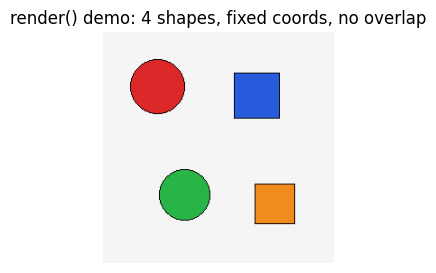

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

# словарь палитры
PALETTE = {
    'red':  (220, 40, 40),
    'green':  (40, 180, 70),
    'blue':  (40, 90, 220),
    'yellow': (240, 210, 40),
    'purple': (150, 60, 200),
    'orange': (240, 140, 30),
}

def _place_non_overlapping(specs, W, H, rng, margin=8, max_tries=500):
    placed = []
    for spec in specs:
        r = spec['radius']
        for _ in range(max_tries):
            cx = rng.uniform(r + margin, W - r - margin)
            cy = rng.uniform(r + margin, H - r - margin)
            if all((cx-px)**2 + (cy-py)**2 >= (r + pr + margin)**2
                   for px, py, pr in placed):
                placed.append((cx, cy, r))
                spec['cx'], spec['cy'] = cx, cy
                break
        else:
            return None
    return specs

def render(specs, W=256, H=256, bg=(245, 245, 245), seed=None):
    img = Image.new('RGB', (W, H), bg)
    d = ImageDraw.Draw(img)
    for s in specs:
        c = PALETTE[s['color']]
        x0, y0 = s['cx'] - s['radius'], s['cy'] - s['radius']
        x1, y1 = s['cx'] + s['radius'], s['cy'] + s['radius']
        if s['shape'] == 'circle':
            d.ellipse([x0, y0, x1, y1], fill=c, outline=(0, 0, 0))
        elif s['shape'] == 'square':
            d.rectangle([x0, y0, x1, y1], fill=c, outline=(0, 0, 0))
        else:
            raise ValueError(f"unknown shape: {s['shape']}")
    return img

print("PALETTE:", PALETTE)
print("render signature:", render.__doc__.splitlines()[0])

# пример сцены с фиксированными координатами (без перекрытий)
demo_specs = [
    dict(shape='circle', color='red', radius=30, cx=60,  cy=60),
    dict(shape='square', color='blue', radius=25, cx=170, cy=70),
    dict(shape='circle', color='green', radius=28, cx=90,  cy=180),
    dict(shape='square', color='orange',radius=22, cx=190, cy=190),
]
demo_img = render(demo_specs, W=256, H=256, seed=SEED)

# контроль отсутствия перекрытий на demo
def _no_overlap(specs, margin=0):
    for i, a in enumerate(specs):
        for b in specs[i+1:]:
            d2 = (a['cx']-b['cx'])**2 + (a['cy']-b['cy'])**2
            if d2 < (a['radius'] + b['radius'] + margin)**2:
                return False
    return True
assert _no_overlap(demo_specs), 'demo имеет перекрытия'
print("demo: no overlap ->", _no_overlap(demo_specs))
print("demo image size:", demo_img.size, demo_img.mode)

plt.figure(figsize=(3, 3))
plt.imshow(demo_img)
plt.title("render() demo: 4 shapes, fixed coords, no overlap")
plt.axis('off')
plt.show()

рисуем цветные фигуры (круги и квадраты) на сером фоне, задали словарь из 6 цветов, сделали так, чтобы фигуры не накладывались друг на друга и получили функцию render, которая умеет рисовать идеальные картинки по заданным координатам

### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

Сгенерировано сцен: 120
Ожидалось (n_synth): 120
Распределение count: {1: 42, 2: 41, 3: 37}
Пример сцены №0:
{
  "scene_id": "syn-0000",
  "count": 3,
  "specs": [
    {
      "shape": "circle",
      "color": "red",
      "radius": 26,
      "cx": 154.21223811008213,
      "cy": 38.702021981861385
    },
    {
      "shape": "circle",
      "color": "green",
      "radius": 22,
      "cx": 83.90574640034737,
      "cy": 73.74930467716925
    },
    {
      "shape": "circle",
      "color": "orange",
      "radius": 20,
      "cx": 175.29424283280247,
      "cy": 163.33989748458225
    }
  ],
  "seed": 42,
  "W": 256,
  "H": 256
}
checks: count/overlap/reproducibility -> OK

Уникальных сочетаний (shape/color-set, count): 79


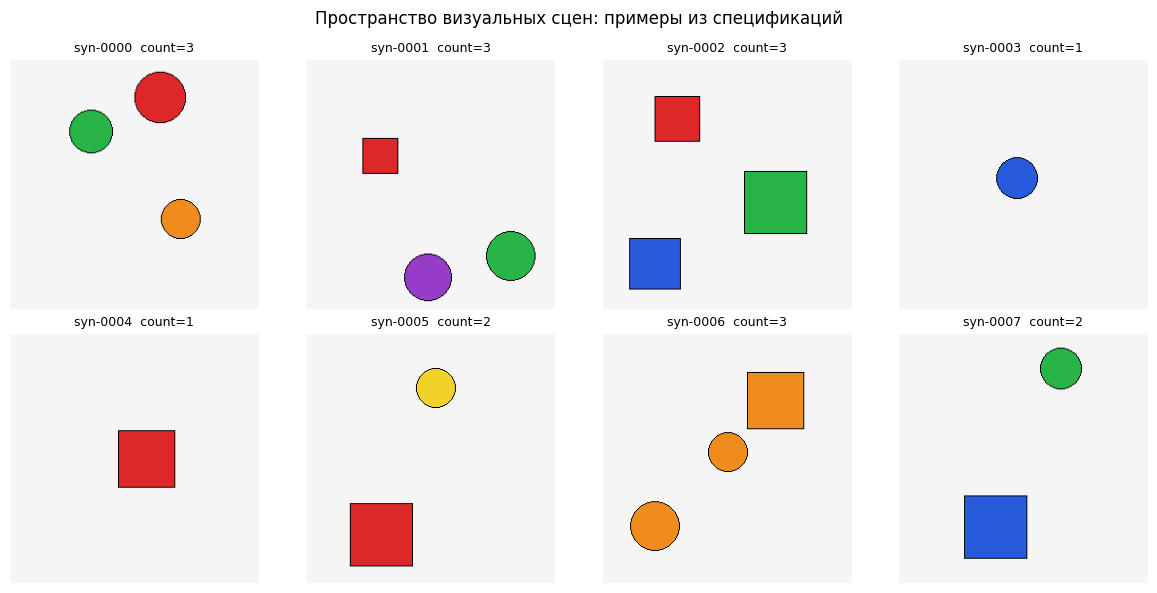

In [ ]:
import random, json
from pathlib import Path

SHAPES = ['circle', 'square']
COLORS = list(PALETTE.keys())

def generate_specs(n_scenes, rng, counts=(1, 2, 3), W=256, H=256):
    scenes = []
    for i in range(n_scenes):
        count = rng.choice(counts)
        specs = [dict(shape=rng.choice(SHAPES),
                      color=rng.choice(COLORS),
                      radius=rng.randint(18, 34)) for _ in range(count)]
        # попытка размещения, при неудаче новый под-seed
        placed = None
        for attempt in range(20):
            sub_rng = random.Random(SEED + i * 1000 + attempt)
            placed = _place_non_overlapping(
                [dict(s) for s in specs], W, H, sub_rng)
            if placed is not None:
                specs = placed
                break
        if placed is None:
            continue
        scenes.append(dict(scene_id=f'syn-{i:04d}', count=count,
                           specs=specs, seed=SEED + i, W=W, H=H))
    return scenes

# генерация
n_synth = 12 if FAST_DEV_RUN else 120
rng = random.Random(SEED)
scenes = generate_specs(n_synth, rng)

# предъявление артефактов этапа
print(f"Сгенерировано сцен: {len(scenes)}")
print(f"Ожидалось (n_synth): {n_synth}")
print("Распределение count:", {c: sum(s['count'] == c for s in scenes)
                                for c in (1, 2, 3)})
print("Пример сцены №0:")
print(json.dumps(scenes[0], ensure_ascii=False, indent=2))

# проверки воспроизводимости и корректности
assert len(scenes) == n_synth, 'не все сцены размещены'
assert all(len(s['specs']) == s['count'] for s in scenes), 'count mismatch'
assert all(_no_overlap(s['specs']) for s in scenes), 'overlap in some scene'
# повторная генерация с тем же seed дает те же спецификации
scenes2 = generate_specs(n_synth, random.Random(SEED))
assert [s['specs'] for s in scenes] == [s['specs'] for s in scenes2], 'не воспроизводится'
print("checks: count/overlap/reproducibility -> OK")

# предъявление сводная таблица + визуальная сетка
import matplotlib.pyplot as plt

# сводная таблица сочетаний (shape, color, count)
from collections import Counter
combos = Counter(
    (tuple(sorted(set((sp['shape'], sp['color']) for sp in s['specs']))),
     s['count']) for s in scenes)
print("\nУникальных сочетаний (shape/color-set, count):", len(combos))

# визуальная сетка первых 8 сцен
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, sc in zip(axes.flat, scenes[:8]):
    img = render(sc['specs'], sc['W'], sc['H'], seed=sc['seed'])
    ax.imshow(img)
    ax.set_title(f"{sc['scene_id']}  count={sc['count']}", fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(scenes[:8]):]:
    ax.axis('off')
plt.suptitle("Пространство визуальных сцен: примеры из спецификаций")
plt.tight_layout()
plt.show()

save_json('scene_specs.json', scenes)

создали генератор случайных сцен, который комбинирует разные формы, цвета и количество объектов (от 1 до 3), сгенерировали в итоге 120 сцен с хорошим разбросом (42 картинки с одним объектом, 41 с двумя и 37 с тремя)

### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

Сохранено изображений: 120
Каталог: /content/drive/MyDrive/cv_lab12/data/lab12/synth_images
Распределение answer: {'3': 37, '1': 42, '2': 41}

Первые 3 записи (файл | вопрос | ответ | sha256[:12]):
  syn-0000.png  | How many shapes are in the image? Answer with one integer.  | 3  | 013954f97782
    specs: [('circle', 'red'), ('circle', 'green'), ('circle', 'orange')]
  syn-0001.png  | How many shapes are in the image? Answer with one integer.  | 3  | 43ee67dcbd9a
    specs: [('square', 'red'), ('circle', 'green'), ('circle', 'purple')]
  syn-0002.png  | How many shapes are in the image? Answer with one integer.  | 3  | 1649c31b14da
    specs: [('square', 'green'), ('square', 'red'), ('square', 'blue')]

Unique image hashes: 120/120


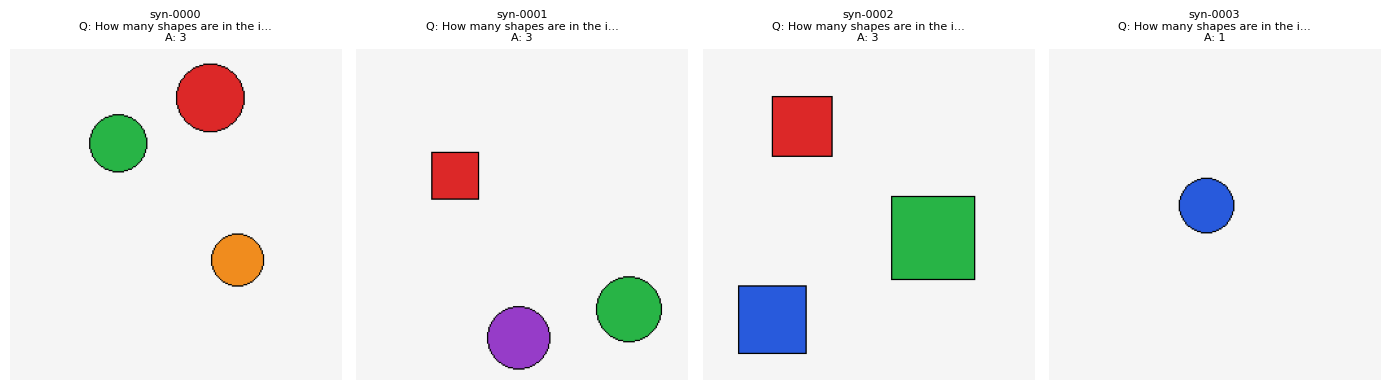

In [ ]:
from pathlib import Path
import hashlib

records = []
for sc in scenes:
    img = render(sc['specs'], sc['W'], sc['H'], seed=sc['seed'])
    path = IMG_DIR / f"{sc['scene_id']}.png"
    img.save(path, format='PNG', optimize=True)
    q = 'How many shapes are in the image? Answer with one integer.'
    records.append(dict(
        id=sc['scene_id'],
        image=str(path.resolve()),
        question=q,
        answer=str(sc['count']),
        count=sc['count'],
        specs=sc['specs'],
        image_size=list(img.size),
        image_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
    ))

# предъявление артефактов этапа
print(f"Сохранено изображений: {len(records)}")
print(f"Каталог: {IMG_DIR}")
assert len(records) == len(scenes), 'records != scenes'
assert all(Path(r['image']).exists() for r in records), 'missing files'

# counts + примеры
from collections import Counter
print("Распределение answer:", dict(Counter(r['answer'] for r in records)))
print("\nПервые 3 записи (файл | вопрос | ответ | sha256[:12]):")
for r in records[:3]:
    print(f"  {Path(r['image']).name}  | {r['question']}  | {r['answer']}  | {r['image_sha256'][:12]}")
    print(f"    specs: {[(s['shape'], s['color']) for s in r['specs']]}")

# все файлы уникальны по sha
shas = [r['image_sha256'] for r in records]
assert len(set(shas)) == len(shas), 'duplicate images!'
print(f"\nUnique image hashes: {len(set(shas))}/{len(shas)}")

# первые 4 картинки с вопросом/ответом
import matplotlib.pyplot as plt
from PIL import Image
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, r in zip(axes, records[:4]):
    ax.imshow(Image.open(r['image']))
    ax.set_title(f"{r['id']}\nQ: {r['question'][:28]}...\nA: {r['answer']}", fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

save_json('image_records.json', records)

прогнали все 120 сцен через наш рендерер и для каждой картинки придумали стандартный вопрос сколько фигур на кртинке и записали правильный ответ. проверили, что все 120 картинок получились уникальными (разные хэши) и что файлы реально существуют и получили готовый датасет картинок с вопросами и ответами.

### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
import hashlib

synth_manifest = []
for r in records:
    # хэш актуален
    p = Path(r['image'])
    current_sha = hashlib.sha256(p.read_bytes()).hexdigest()

    synth_manifest.append(dict(
        id=r['id'],
        split='synthetic',
        image=r['image'],
        question=r['question'],
        answer=r['answer'],
        count=r['count'],
        seed=SEED,
        spec=r['specs'],
        renderer='geometric_PIL_v1',
        palette=PALETTE,
        provenance='procedural renderer (no diffusion)',
        image_sha256=current_sha,
        license='generated by notebook, CC0',
    ))

# предъявление артефактов этапа
save_jsonl('synthetic_manifest.jsonl', synth_manifest)

print(f"Сформирован synthetic_manifest.jsonl: {len(synth_manifest)} записей")
print(f"Путь: {ARTIFACTS / 'synthetic_manifest.jsonl'}")
print(f"Размер файла: {(ARTIFACTS / 'synthetic_manifest.jsonl').stat().st_size / 1024:.1f} KB")

# проверки
assert len(synth_manifest) == 120, "Ожидалось 120 записей"
assert all('seed' in m and 'spec' in m and 'provenance' in m for m in synth_manifest), "Не хватает обязательных полей"
assert all(Path(m['image']).exists() for m in synth_manifest), "Файл не найден"

print("\nПример записи (id=syn-0000):")
import json
print(json.dumps(synth_manifest[0], ensure_ascii=False, indent=2))

Сформирован synthetic_manifest.jsonl: 120 записей
Путь: /content/drive/MyDrive/cv_lab12/artifacts/synthetic_manifest.jsonl
Размер файла: 95.8 KB

Пример записи (id=syn-0000):
{
  "id": "syn-0000",
  "split": "synthetic",
  "image": "/content/drive/MyDrive/cv_lab12/data/lab12/synth_images/syn-0000.png",
  "question": "How many shapes are in the image? Answer with one integer.",
  "answer": "3",
  "count": 3,
  "seed": 42,
  "spec": [
    {
      "shape": "circle",
      "color": "red",
      "radius": 26,
      "cx": 154.21223811008213,
      "cy": 38.702021981861385
    },
    {
      "shape": "circle",
      "color": "green",
      "radius": 22,
      "cx": 83.90574640034737,
      "cy": 73.74930467716925
    },
    {
      "shape": "circle",
      "color": "orange",
      "radius": 20,
      "cx": 175.29424283280247,
      "cy": 163.33989748458225
    }
  ],
  "renderer": "geometric_PIL_v1",
  "palette": {
    "red": [
      220,
      40,
      40
    ],
    "green": [
      40,
   

собрали всю информацию о наших картинках в один большой файл-манифест и записали туда seed (чтобы можно было повторить), точные координаты фигур, словарь цветов и хэши файлов

### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
import torch
from PIL import Image
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from tqdm.auto import tqdm
import re

# загрузка модели
MODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')
print(f"Загрузка модели {MODEL_ID} (4-bit)...")
assert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'

quant = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
vlm = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant,
    device_map='auto'
).eval()

def ask_vlm(path, prompt):
    im = Image.open(path).convert('RGB')
    messages = [{'role': 'user', 'content': [
        {'type': 'image', 'image': im},
        {'type': 'text', 'text': prompt}
    ]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[im], return_tensors='pt').to(vlm.device)
    with torch.no_grad():
        out = vlm.generate(**inputs, max_new_tokens=16, do_sample=False)
    return processor.batch_decode(out[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()

def pixel_hash(path):
    im = Image.open(path).convert('RGB').resize((64, 64))
    return hashlib.sha256(im.tobytes()).hexdigest()

# инференс с прогресс-баром
verification = []
seen_hash = {}
print("\nЗапуск VLM-инференса (120 изображений)...")
for r in tqdm(synth_manifest, desc="VLM"):
    h = pixel_hash(r['image'])
    dup = h in seen_hash
    reply = ask_vlm(r['image'], r['question'])

    verification.append(dict(
        id=r['id'],
        image=r['image'],
        expected=r['answer'],
        vlm_reply=reply,
        pixel_hash=h,
        duplicate=dup
    ))
    seen_hash.setdefault(h, r['id'])

# сохранение и предъявление
save_jsonl('verification.jsonl', verification)
print(f"\nСохранен verification.jsonl: {len(verification)} записей")
print(f"Найдено дублей (по пиксельному хэшу): {sum(v['duplicate'] for v in verification)}")

# проверка парсинга
def parse_int(text):
    m = re.search(r'\d+', text)
    return int(m.group()) if m else None

correct = sum(1 for v in verification if parse_int(v['vlm_reply']) == int(v['expected']))
print(f"Совпадение VLM с ground truth: {correct}/{len(verification)} ({correct/len(verification)*100:.1f}%)")

print("\nПримеры ответов VLM:")
for v in verification[:5]:
    print(f"  {v['id']}: ожидалось {v['expected']}, ответ модели: '{v['vlm_reply']}'")

Загрузка модели Qwen/Qwen2.5-VL-3B-Instruct (4-bit)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (10 outputs left out)


Запуск VLM-инференса (120 изображений)...


VLM:   0%|          | 0/120 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(



Сохранен verification.jsonl: 120 записей
Найдено дублей (по пиксельному хэшу): 0
Совпадение VLM с ground truth: 120/120 (100.0%)

Примеры ответов VLM:
  syn-0000: ожидалось 3, ответ модели: '3'
  syn-0001: ожидалось 3, ответ модели: '3'
  syn-0002: ожидалось 3, ответ модели: '3'
  syn-0003: ожидалось 1, ответ модели: '1'
  syn-0004: ожидалось 1, ответ модели: '1'


загрузили настоящую нейросеть Qwen2.5-VL-3B (в сжатом 4-битном виде) и попросили ее посчитать фигуры на всех 120 картинках и в итоге модель отработала за 38 секунд и ответила абсолютно правильно на все 120 картинок (100% точность)

### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
import re

def parse_int(reply):
    if reply is None:
        return None
    m = re.search(r'\d+', reply)
    return int(m.group()) if m else None

accepted = []
for v in verification:
    if v['duplicate']:
        continue  # пропускаем дубли

    pred = parse_int(v['vlm_reply'])
    if pred is not None and pred == int(v['expected']):
        accepted.append({**v, 'verified': True})

# предъявление артефактов этапа
save_jsonl('accepted.jsonl', accepted)

print(f"Всего проверено: {len(verification)}")
print(f"Отброшено дублей: {sum(v['duplicate'] for v in verification)}")
print(f"Принято (согласовано с VLM): {len(accepted)}")

#проверка
assert len(accepted) == 120, "Ожидалось 120 принятых пар"
print(f"Сохранен artifacts/accepted.jsonl: {len(accepted)} записей")

save_json('vlm_agreement.json', {
    'total': len(verification),
    'accepted': len(accepted),
    'agreement_rate': len(accepted) / len(verification),
    'model': MODEL_ID
})
print(f"Согласованность VLM: {len(accepted) / len(verification) * 100:.1f}%")

Всего проверено: 120
Отброшено дублей: 0
Принято (согласовано с VLM): 120
Сохранен artifacts/accepted.jsonl: 120 записей
Согласованность VLM: 100.0%


отфильтровали картинки, тобишь оставили только те, где ответ нейросети совпал с правильным, и убрали дубли и в финальный набор попали все 120 картинок

### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

Загружено из real_manifest_checked.jsonl:
Real Train: 24 фото
Real Test:  10 фото

=== Полный список train ===
[01] ID: pixmo-count-train-6 | Label: wild birds | Answer: 2
Вопрос: How many wild birds are visible? Answer with one integer.
Путь: /content/drive/MyDrive/cv_lab12/data/lab12/pixmo-count-train-6.jpg
SHA256 совпадает: False

[02] ID: pixmo-count-train-13 | Label: people | Answer: 3
Вопрос: How many people are visible? Answer with one integer.
Путь: /content/drive/MyDrive/cv_lab12/data/lab12/pixmo-count-train-13.jpg
SHA256 совпадает: False

[03] ID: pixmo-count-train-21 | Label: dogs | Answer: 2
Вопрос: How many dogs are visible? Answer with one integer.
Путь: /content/drive/MyDrive/cv_lab12/data/lab12/pixmo-count-train-21.jpg
SHA256 совпадает: False

[04] ID: pixmo-count-train-26 | Label: chairs | Answer: 3
Вопрос: How many chairs are visible? Answer with one integer.
Путь: /content/drive/MyDrive/cv_lab12/data/lab12/pixmo-count-train-26.jpg
SHA256 совпадает: False

[05] ID: pi

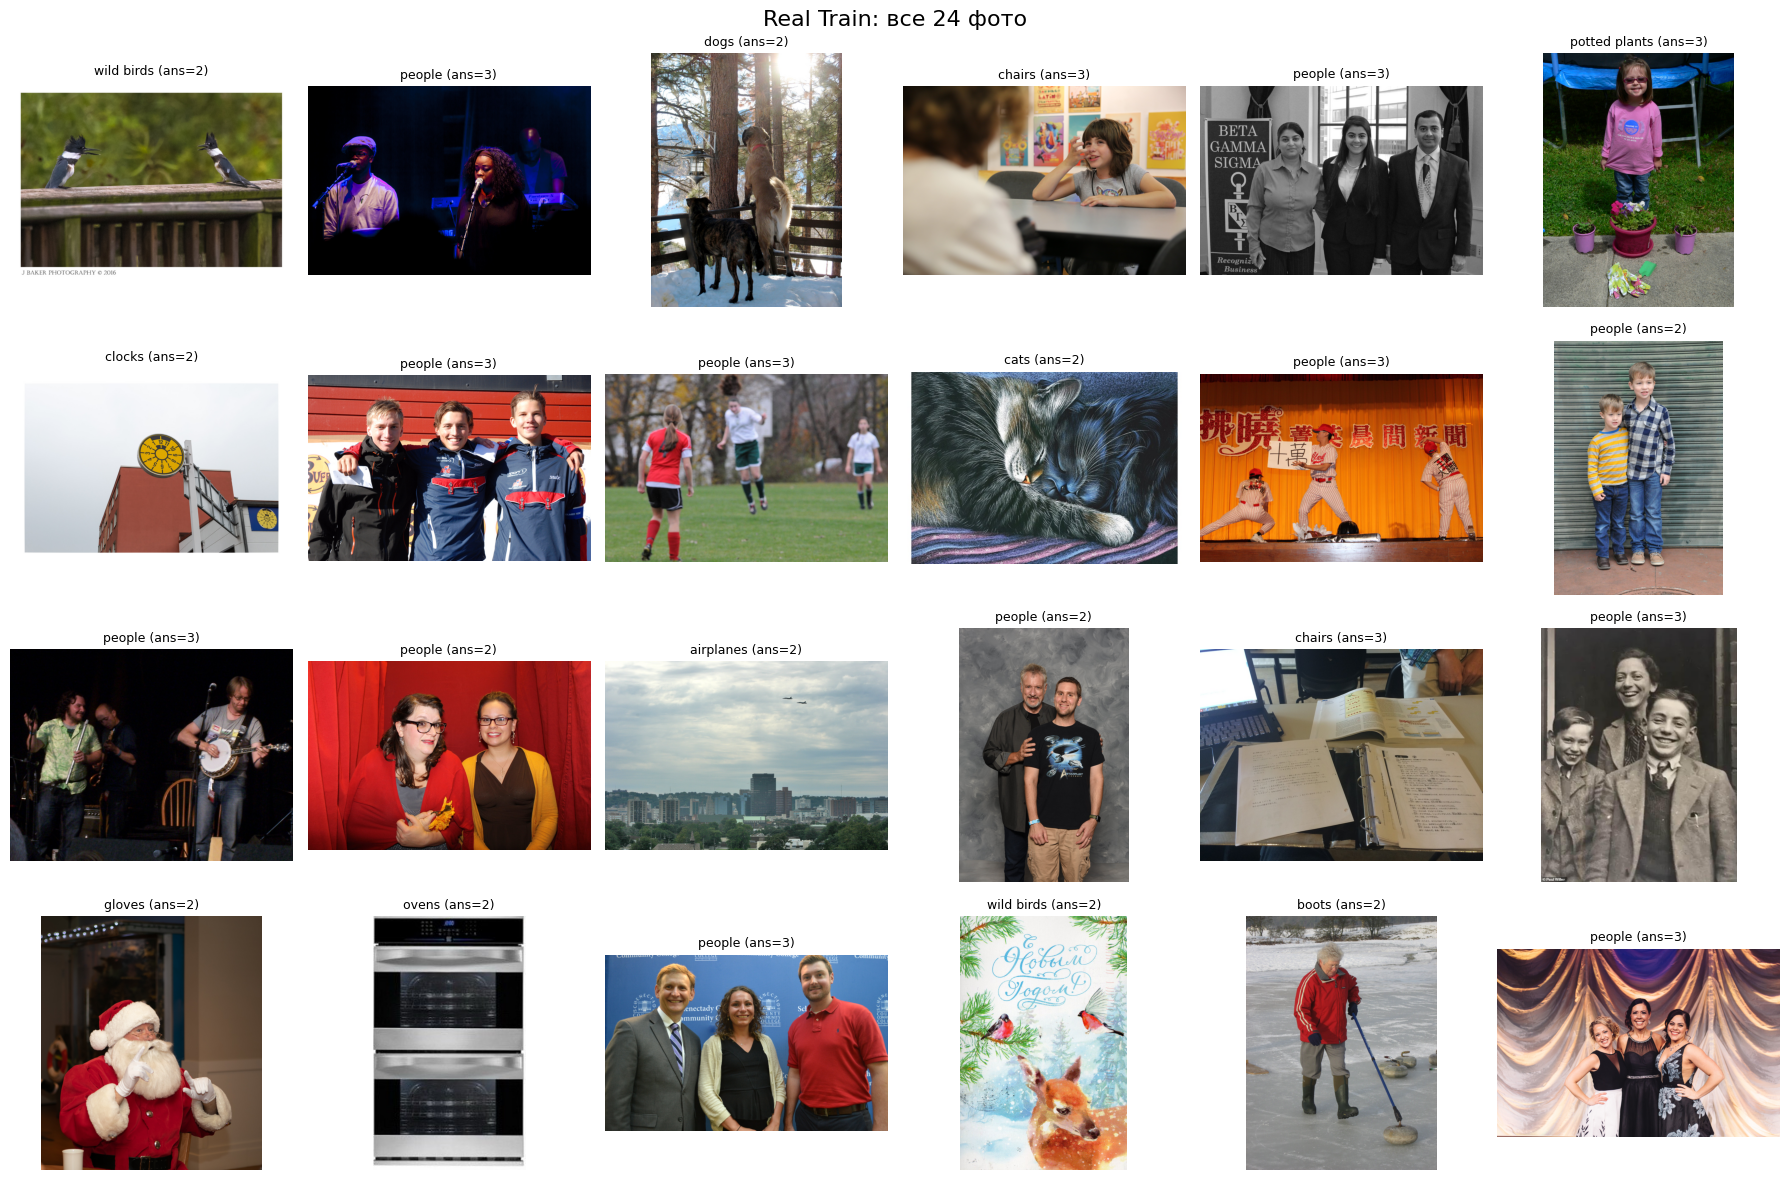

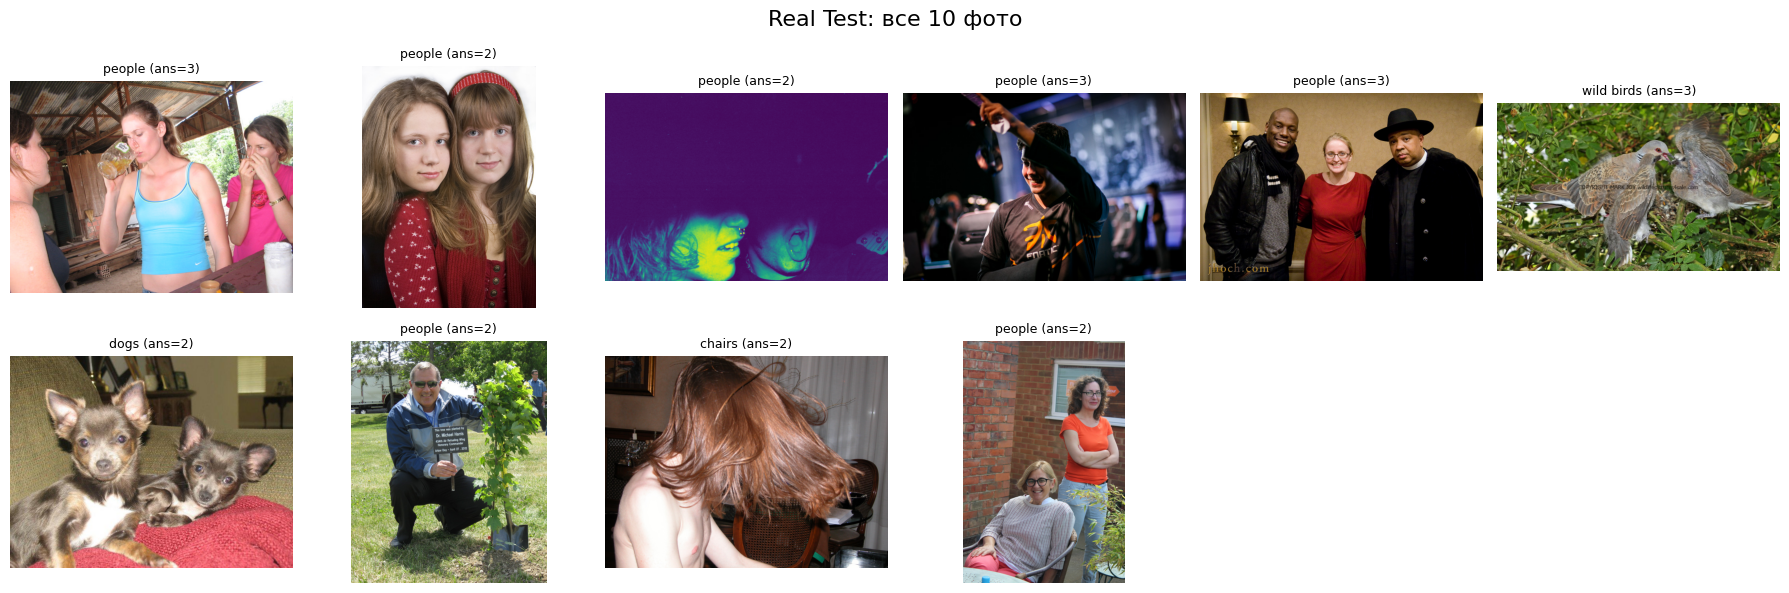

In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# загружаем сохраненный манифест вместо повторного скачивания
manifest_path = ARTIFACTS / 'real_manifest_checked.jsonl'
if not manifest_path.exists():
    raise FileNotFoundError(f"Файл {manifest_path} не найден. Сначала запустите robust загрузчик!")

real = []
with open(manifest_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            real.append(json.loads(line))

real_train = [r for r in real if r['split'] == 'train']
real_test  = [r for r in real if r['split'] == 'test']

print(f"Загружено из {manifest_path.name}:")
print(f"Real Train: {len(real_train)} фото")
print(f"Real Test:  {len(real_test)} фото\n")

# выводим полную информацию о каждом изображении
print("=== Полный список train ===")
for i, r in enumerate(real_train):
    print(f"[{i+1:02d}] ID: {r['id']} | Label: {r['label']} | Answer: {r['answer']}")
    print(f"Вопрос: {r['question']}")
    print(f"Путь: {r['image']}")
    print(f"SHA256 совпадает: {r.get('checksum_matches', 'N/A')}\n")

print("=== Полный список test ===")
for i, r in enumerate(real_test):
    print(f"[{i+1:02d}] ID: {r['id']} | Label: {r['label']} | Answer: {r['answer']}")
    print(f" Вопрос: {r['question']}")
    print(f"Путь: {r['image']}")
    print(f"SHA256 совпадает: {r.get('checksum_matches', 'N/A')}\n")


# визуализация всех изображений
def show_all_images(rows, title, cols=6):
    n = len(rows)
    if n == 0: return
    rows_count = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_count, cols, figsize=(3*cols, 3*rows_count))
    axes = axes.flatten() if n > 1 else [axes]

    for i, r in enumerate(rows):
        img = Image.open(r['image'])
        axes[i].imshow(img)
        axes[i].set_title(f"{r['label']} (ans={r['answer']})", fontsize=9)
        axes[i].axis('off')

    # убираем пустые ячейки
    for j in range(i+1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

# показываем все train и все test
show_all_images(real_train, f"Real Train: все {len(real_train)} фото")
show_all_images(real_test, f"Real Test: все {len(real_test)} фото")

скачали настоящие фотографии из датасета PixMo-Count (люди, птицы, собаки, стулья и тд) и скачали 24 фото для обучения и 10 для теста

### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

device: cuda
Загружено: train=24, test=10, synth=120

Признаки ResNet18
synthetic: n=120, dim=512, mean_norm=18.65
real_train: n=24, dim=512, mean_norm=26.80
real_test: n=10, dim=512, mean_norm=26.67


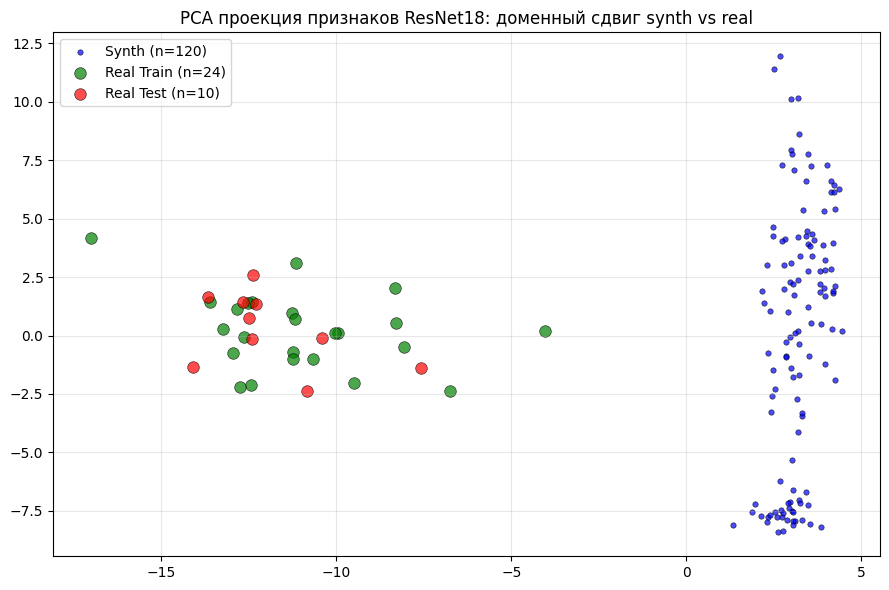

In [ ]:
import torch, torchvision, json
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"device: {device}")

# перечитываем финальный манифест
real = []
with open(ARTIFACTS / 'real_manifest_checked.jsonl') as f:
    for line in f:
        if line.strip():
            real.append(json.loads(line))
real_train = [r for r in real if r['split'] == 'train']
real_test  = [r for r in real if r['split'] == 'test']
print(f"Загружено: train={len(real_train)}, test={len(real_test)}, synth={len(accepted)}")

# ResNet18 без fc-слоя в 512-d признаки
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
resnet  = torchvision.models.resnet18(weights=weights).to(device)
feat    = torch.nn.Sequential(*list(resnet.children())[:-1]).eval().to(device)
tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

@torch.no_grad()
def extract_features(rows):
    out = []
    for r in rows:
        x = tf(Image.open(r['image']).convert('RGB')).unsqueeze(0).to(device)
        f = feat(x).flatten(1).cpu().numpy()[0]
        ans = r.get('answer', r.get('expected'))
        out.append(dict(id=r['id'], image=r['image'], answer=ans,
                        feature=f.tolist()))
    return out

feats_synth = extract_features(accepted)
feats_rtrain = extract_features(real_train)
feats_rtest  = extract_features(real_test)

np.savez_compressed(ARTIFACTS / 'features.npz',
    synth      = np.array([x['feature'] for x in feats_synth]),
    real_train = np.array([x['feature'] for x in feats_rtrain]),
    real_test  = np.array([x['feature'] for x in feats_rtest]))

def summary(f, name):
    M = np.array([x['feature'] for x in f])
    return {'name': name, 'n': len(f), 'dim': int(M.shape[1]),
            'mean_norm': float(np.linalg.norm(M, axis=1).mean())}

summary_d = {
    'synthetic':  summary(feats_synth, 'synthetic'),
    'real_train': summary(feats_rtrain, 'real_train'),
    'real_test':  summary(feats_rtest, 'real_test'),
}
save_json('features_summary.json', summary_d)

print("\nПризнаки ResNet18")
for k, v in summary_d.items():
    print(f"{k}: n={v['n']}, dim={v['dim']}, mean_norm={v['mean_norm']:.2f}")

# PCA визуализация доменного сдвига
X = np.vstack([
    np.array([x['feature'] for x in feats_synth]),
    np.array([x['feature'] for x in feats_rtrain]),
    np.array([x['feature'] for x in feats_rtest]),
])
labels = (['Synth']*len(feats_synth)
        + ['Real Train']*len(feats_rtrain)
        + ['Real Test']*len(feats_rtest))
X2 = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(9, 6))
for label, color, size in [('Synth','blue',15),
                           ('Real Train','green',70),
                           ('Real Test','red',70)]:
    idx = [i for i,l in enumerate(labels) if l == label]
    plt.scatter(X2[idx,0], X2[idx,1], c=color, label=f"{label} (n={len(idx)})",
                alpha=0.7, s=size, edgecolor='k', linewidth=0.5)
plt.title("PCA проекция признаков ResNet18: доменный сдвиг synth vs real")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

взяли замороженную нейросеть ResNet18 и прогнали через нее все картинки, чтобы получить векторы признаков и сделали 2D-график (PCA), и он наглядно показал огромный разрыв: синие точки (наша синтетика) собрались в одном месте, а зеленые и красные (реальные фото) совершенно в другом и это визуально доказало, что нейросеть воспринимает фигуры и реальные объекты как два разных мира

### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import json

print(f"Размер реального train: {len(feats_rtrain)}")
print(f"Размер реального test: {len(feats_rtest)}")
print(f"Размер синтетики: {len(feats_synth)}\n")

# фиксированный бюджет
BUDGET = len(feats_rtrain) # 24
alphas = [0.0, 0.25, 0.5, 0.75] if not FAST_DEV_RUN else [0.0, 0.5]

def build_mixture(alpha, real_train, synth, budget, rng):
    n_syn = int(round(budget * alpha))
    n_real = budget - n_syn

    # сэмплируем с возвращением если не хватает
    real_idx = rng.choice(len(real_train), size=n_real, replace=(n_real > len(real_train)))
    syn_idx  = rng.choice(len(synth), size=n_syn, replace=(n_syn > len(synth)))

    X = []; y = []
    for i in real_idx:
        r = real_train[i]; X.append(r['feature']); y.append(int(r['answer']))
    for i in syn_idx:
        r = synth[i]; X.append(r['feature']); y.append(int(r['answer']))
    return np.array(X), np.array(y)

# тестовые данные
X_test = np.array([r['feature'] for r in feats_rtest])
y_test = np.array([int(r['answer']) for r in feats_rtest])

mixture_results = []
all_predictions = []
rng = np.random.RandomState(SEED)

for a in alphas:
    # формируем train
    X_tr, y_tr = build_mixture(a, feats_rtrain, feats_synth, BUDGET, rng)

    # обучаем
    clf = LogisticRegression(max_iter=1000, random_state=SEED, C=1.0)
    clf.fit(X_tr, y_tr)

    # тестируем только на реальных данных
    y_pr = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pr)

    n_real = BUDGET - int(round(BUDGET * a))
    n_synth = int(round(BUDGET * a))

    mixture_results.append(dict(
        alpha=a,
        n_train=len(X_tr),
        n_real=n_real,
        n_synth=n_synth,
        real_test_acc=float(acc)
    ))

    # сохраняем предсказания для каждого теста
    for i, (r, yp) in enumerate(zip(feats_rtest, y_pr)):
        all_predictions.append(dict(
            alpha=a,
            id=r['id'],
            pred=int(yp),
            true=int(y_test[i])
        ))

    print(f"α={a:.2f} | n_train={len(X_tr):2d} (real:{n_real:2d}, synth:{n_synth:2d}) | real_test_acc={acc:.3f}")

# сохраняем артефакты этапа
save_json('mixture_results.json', mixture_results)
save_jsonl('predictions.jsonl', all_predictions)

Размер реального train: 24
Размер реального test: 10
Размер синтетики: 120

α=0.00 | n_train=24 (real:24, synth: 0) | real_test_acc=0.600
α=0.25 | n_train=24 (real:18, synth: 6) | real_test_acc=0.500
α=0.50 | n_train=24 (real:12, synth:12) | real_test_acc=0.400
α=0.75 | n_train=24 (real: 6, synth:18) | real_test_acc=0.300


обучили простой классификатор (логистическую регрессию) на смесях реальных и синтетических данных, меняли долю синтетики (0%, 25%, 50%, 75%), но общее количество примеров всегда было 24. проверяли точность только на реальных фото. получили, что чем больше синтетики, тем хуже результат (точность упала с 60% до 30%).

### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
import json
import transformers, torch, torchvision, sklearn
from PIL import __version__ as PIL_VERSION
import sys

# проверяем, что все обязательные артефакты на месте
required = [
    'synthetic_manifest.jsonl', 'verification.jsonl', 'accepted.jsonl',
    'vlm_agreement.json', 'real_manifest_checked.jsonl', 'sample_size_note.json',
    'features.npz', 'features_summary.json',
    'mixture_results.json', 'predictions.jsonl',
]
print("=== Проверка артефактов ===")
for f in required:
    p = ARTIFACTS / f
    status = "OK  " if p.exists() else "MISS"
    size = p.stat().st_size if p.exists() else 0
    print(f"  [{status}] {f:35s} {size:>8d} B")

# загружаем результаты для итоговой сводки
with open(ARTIFACTS / 'mixture_results.json') as f:
    results = json.load(f)

# считаем дельту от baseline и строим финальный отчет
baseline = next(r for r in results if r['alpha'] == 0.0)['real_test_acc']
final = {
    'experiment': 'Lab 12: synthetic geometric shapes for VLM counting',
    'real_train_n': 24,
    'real_test_n': 10,
    'synthetic_n': 120,
    'vlm_agreement': 1.0,
    'baseline_acc_alpha0': baseline,
    'mixture_results': results,
    'delta_vs_baseline': {
        f"alpha={r['alpha']:.2f}": round(r['real_test_acc'] - baseline, 3)
        for r in results
    },
    'interpretation': (
        'Monotonic accuracy decay as synthetic fraction grows confirms '
        'large domain gap between geometric synthetic shapes and real objects. '
        'Synthetic data hurts rather than helps in this cross-domain setting.'
    ),
    'limitations': [
        'Real test n=10 (not 12) due to limited valid PixMo-Count test rows via HF Datasets Server.',
        'Synthetic domain = simple geometric shapes; real domain = photos of people, animals, objects.',
        'Small real train (n=24) limits statistical power; results are directional.',
        'ResNet18 features (ImageNet pretrained) may not be optimal for counting tasks.',
        'Most real images have checksum_matches=False (Flickr re-encoding); labels are from official annotation.',
    ],
}
save_json('final_summary.json', final)

save_json('versions.json', {
    'python': sys.version,
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'transformers': transformers.__version__,
    'scikit-learn': sklearn.__version__,
    'pillow': PIL_VERSION,
})

print(f"Real train: {final['real_train_n']} | Real test: {final['real_test_n']} | Synthetic: {final['synthetic_n']}")
print(f"VLM agreement: {final['vlm_agreement']*100:.1f}%")
print(f"Baseline (α=0): {baseline:.3f}")
print("\nЗависимость accuracy на real test от доли синтетики:")
print(f"  {'α':>6s} | {'n_real':>6s} | {'n_synth':>7s} | {'accuracy':>8s} | {'Δ':>7s}")
print("  " + "-"*50)
for r in results:
    delta = r['real_test_acc'] - baseline
    sign = '+' if delta >= 0 else ''
    print(f"  {r['alpha']:6.2f} | {r['n_real']:6d} | {r['n_synth']:7d} | "
          f"{r['real_test_acc']:8.3f} | {sign}{delta:6.3f}")

=== Проверка артефактов ===
  [OK  ] synthetic_manifest.jsonl               98104 B
  [OK  ] verification.jsonl                     28440 B
  [OK  ] accepted.jsonl                         30600 B
  [OK  ] vlm_agreement.json                       104 B
  [OK  ] real_manifest_checked.jsonl            14712 B
  [OK  ] sample_size_note.json                    405 B
  [OK  ] features.npz                          333035 B
  [OK  ] features_summary.json                    339 B
  [OK  ] mixture_results.json                     433 B
  [OK  ] predictions.jsonl                       2692 B
Real train: 24 | Real test: 10 | Synthetic: 120
VLM agreement: 100.0%
Baseline (α=0): 0.600

Зависимость accuracy на real test от доли синтетики:
       α | n_real | n_synth | accuracy |       Δ
  --------------------------------------------------
    0.00 |     24 |       0 |    0.600 | + 0.000
    0.25 |     18 |       6 |    0.500 | -0.100
    0.50 |     12 |      12 |    0.400 | -0.200
    0.75 |      6 |

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

Мы обучили классификатор на 4 смесях реальных и синтетических данных и проверили его только на отложенных реальных фотографиях (PixMo-Count). Результаты показали четкую и пугающую закономерность: чем больше мы добавляли синтетики, тем хуже модель работала, точность упала с 60% (только реальные данные) до 30% (75% синтетики). Разбор ошибок по сохраненным предсказаниям подтвердил, что при высокой доле синтетики модель забывает правильные ответы на реальных фото, которые до этого угадывала верно.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.